In [8]:
# Telecom Customer Churn - Exploratory Data Analysis

import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_preprocessing import load_raw_data, clean_data, data_quality_report
from src.utils import (
    plot_churn_by_categories,
    plot_numerical_vs_churn,
    plot_correlation_heatmap
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

Load and Clean Data

In [9]:
df_raw = load_raw_data("../data/Telecom_Churn.csv")
df = clean_data(df_raw)

print("First 5 rows:")
display(df.head())

Raw data loaded successfully. Shape: (7043, 21)
Dropped 11 rows with missing TotalCharges.
Data cleaned successfully. Final shape: (7032, 20)
First 5 rows:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


Data Quality Report

In [10]:
data_quality_report(df)

DATA QUALITY REPORT
Shape: (7032, 20)

Missing values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Data types:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
Mon

Target Distribution

Churn Distribution:
Churn
0    5163
1    1869
Name: count, dtype: int64

Percentage:
Churn
0    73.4
1    26.6
Name: proportion, dtype: float64


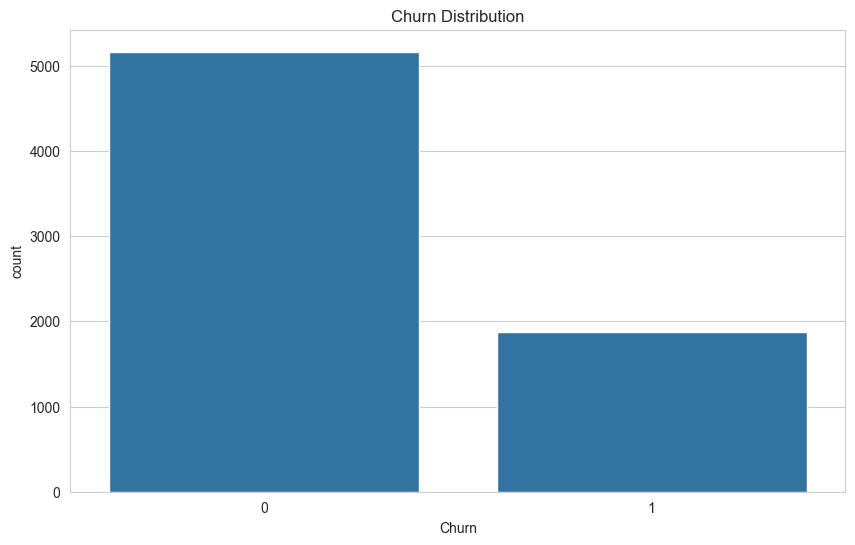

In [11]:
print("Churn Distribution:")
print(df["Churn"].value_counts())
print("\nPercentage:")
print(df["Churn"].value_counts(normalize=True).round(3) * 100)

sns.countplot(data=df, x="Churn")
plt.title("Churn Distribution")
plt.show()

Categorical Features vs Churn

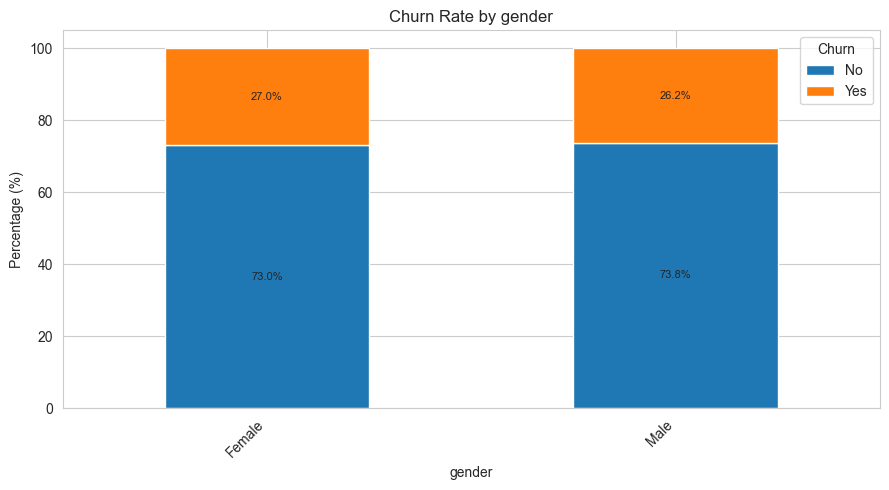

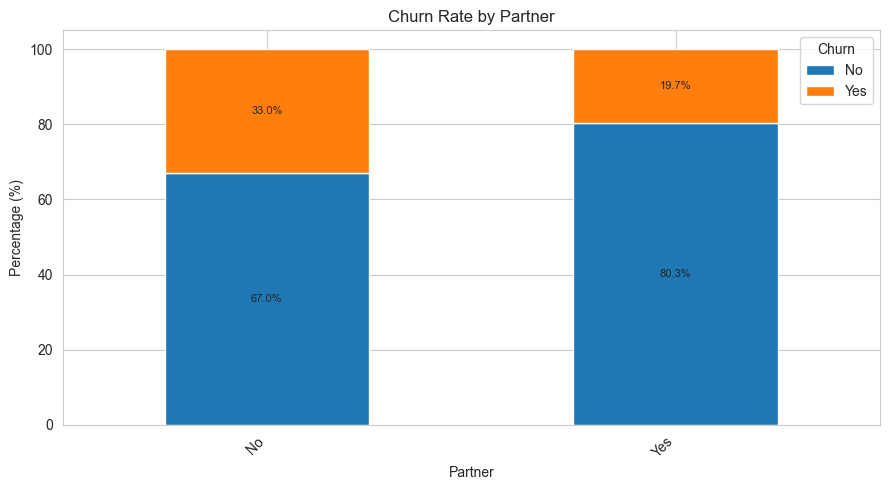

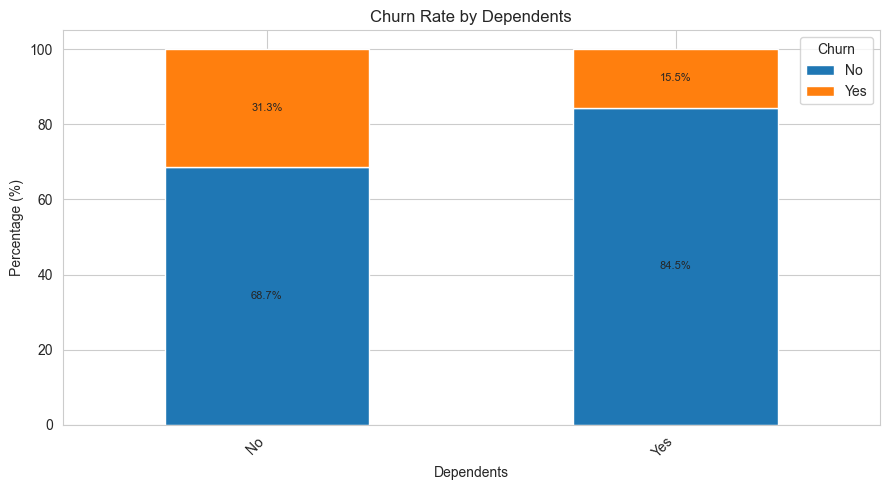

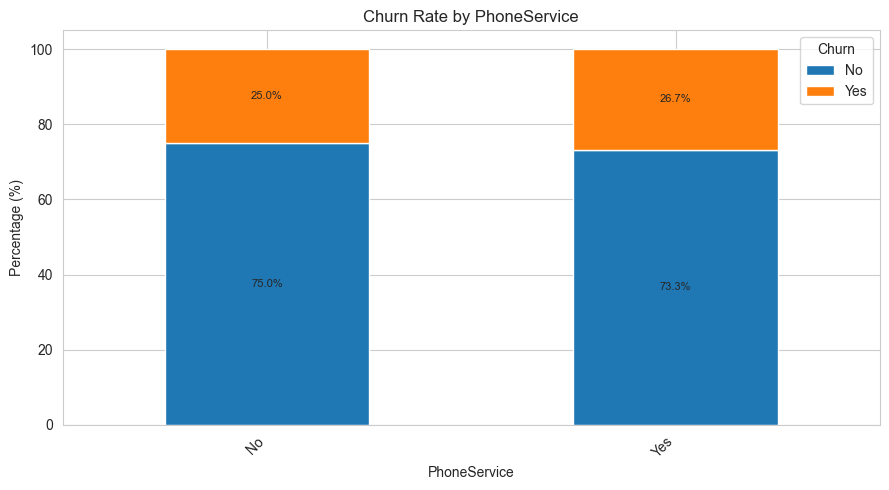

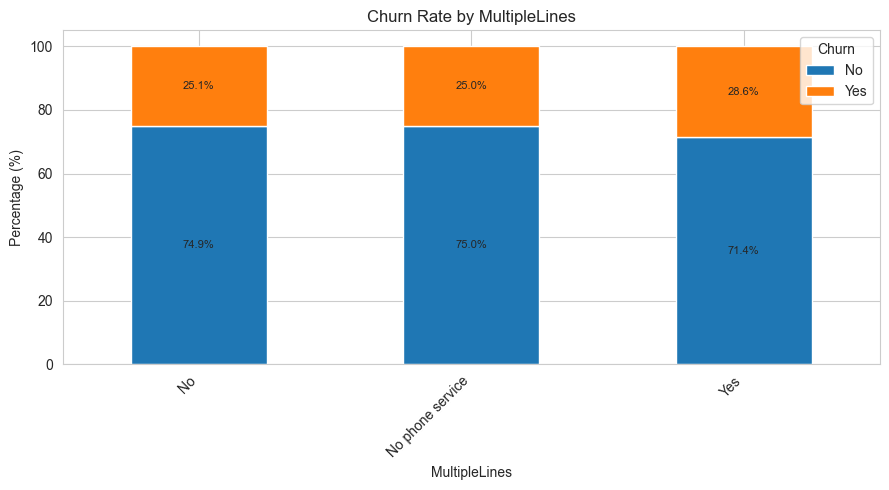

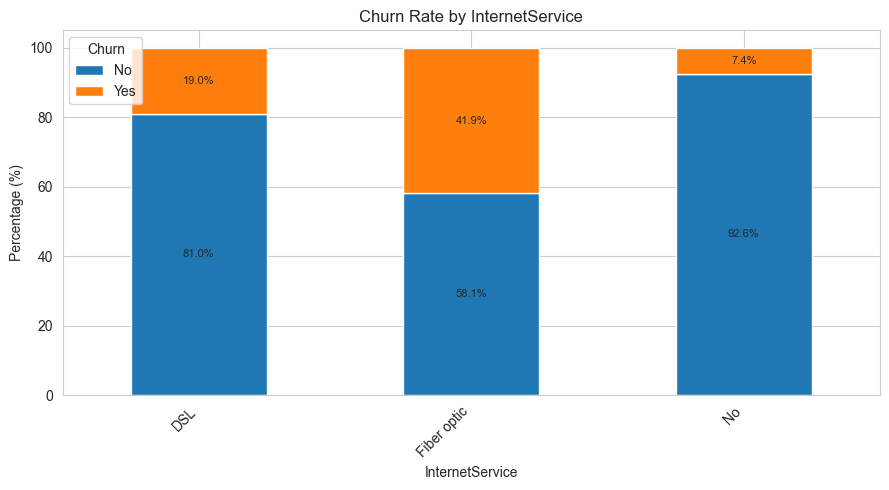

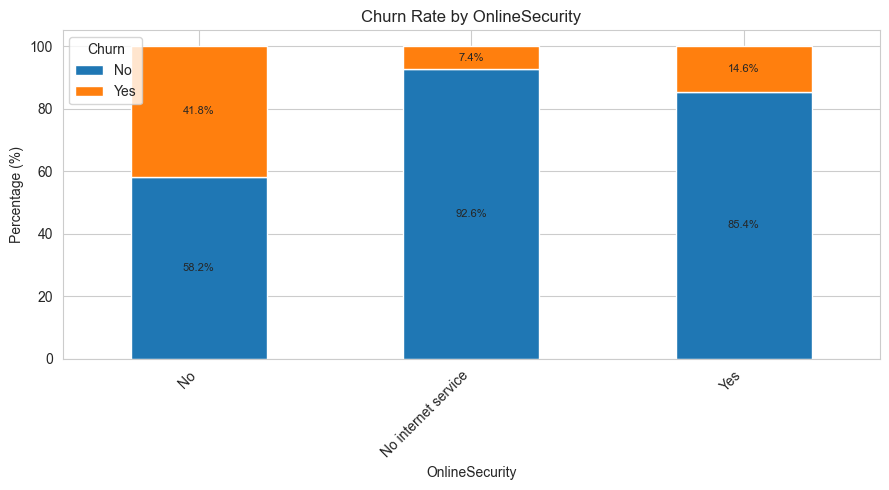

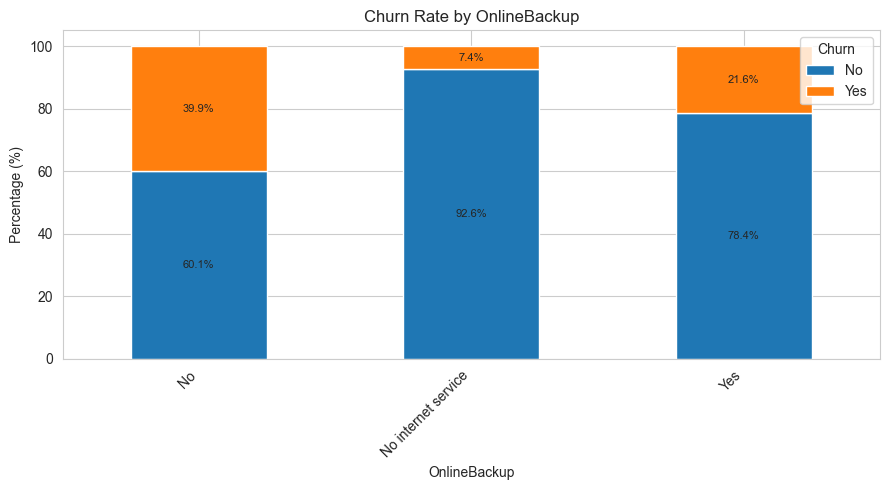

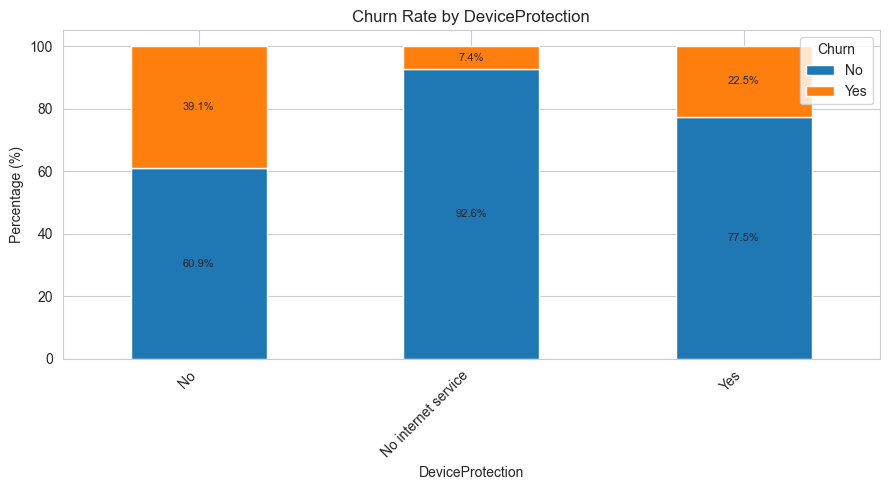

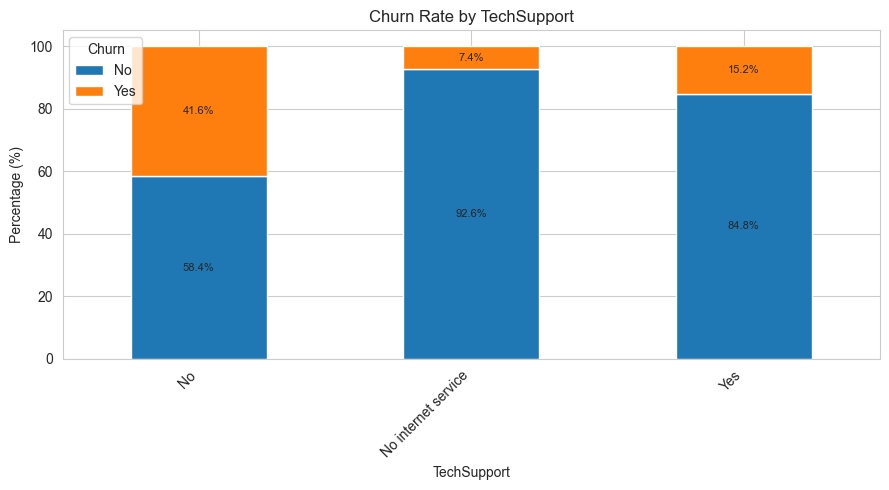

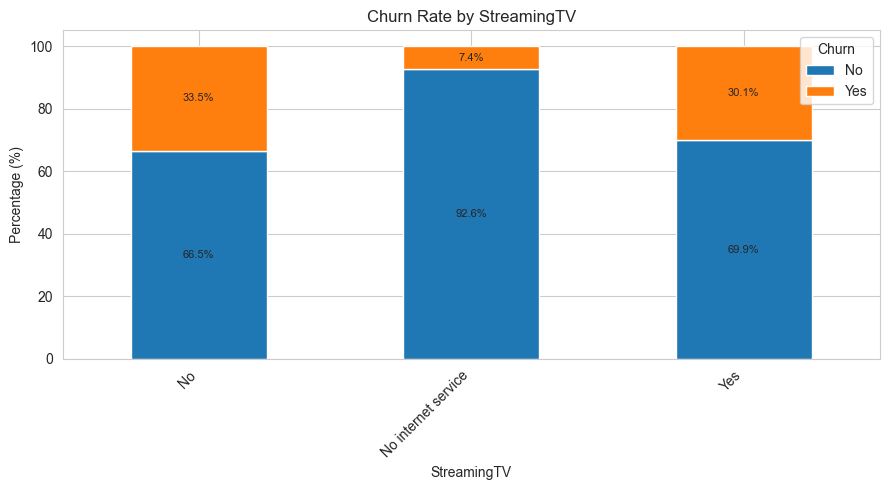

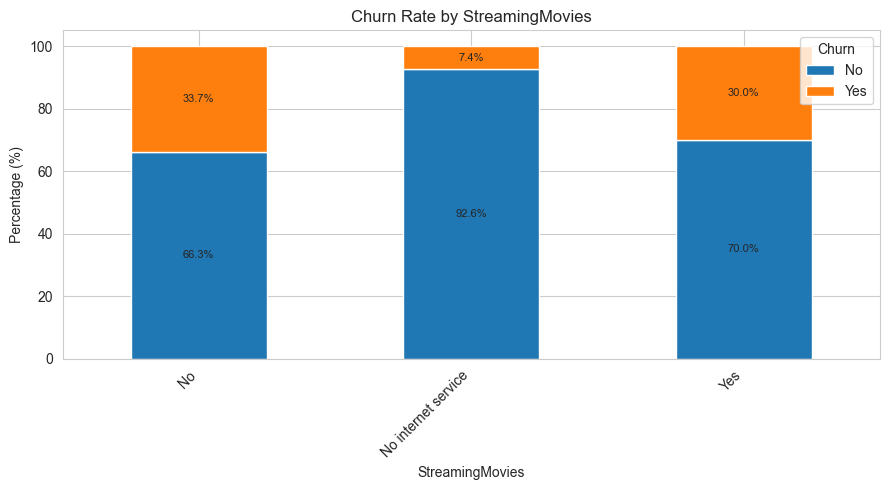

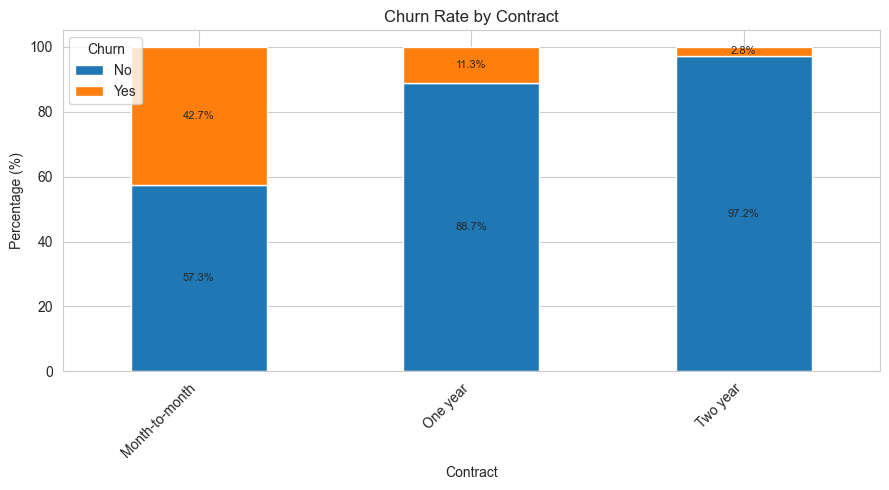

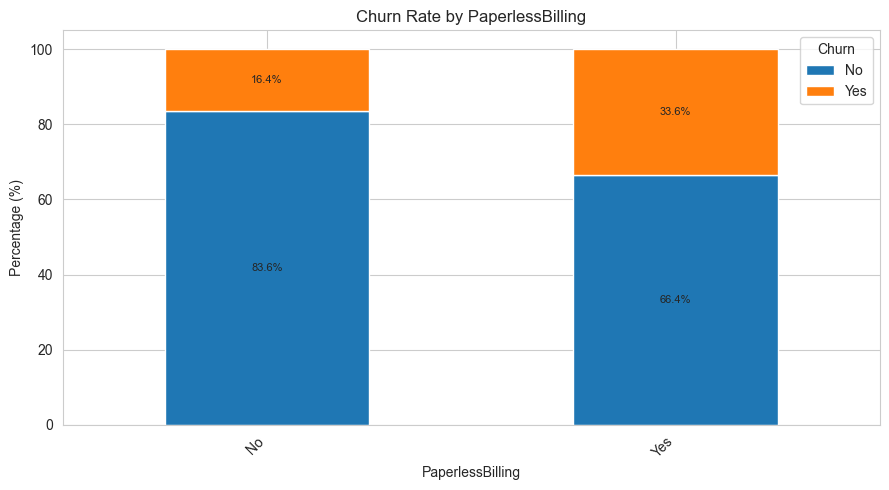

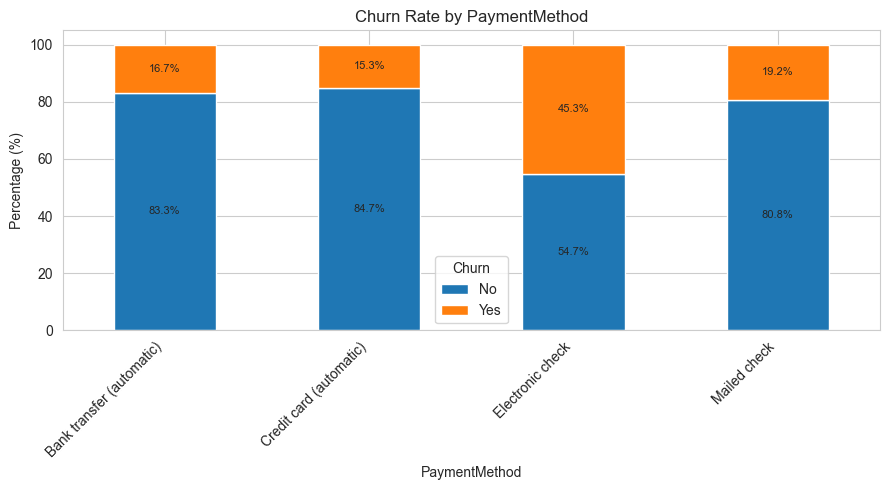

In [12]:
categorical_cols = [
    "gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
    "PaperlessBilling", "PaymentMethod"
]

plot_churn_by_categories(df, categorical_cols)

Numerical Features vs Churn

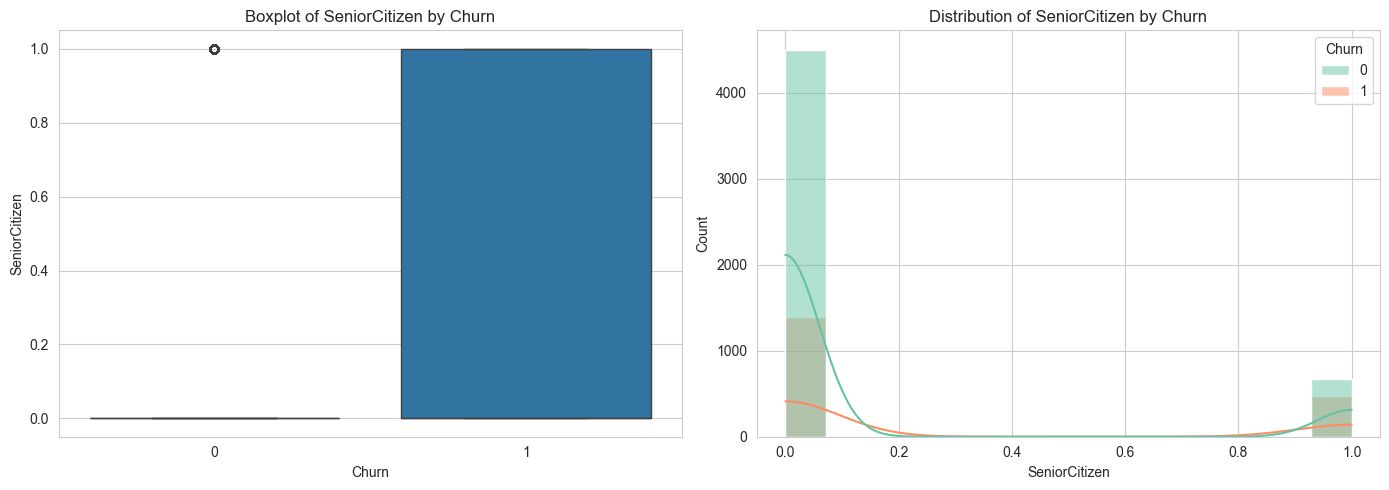

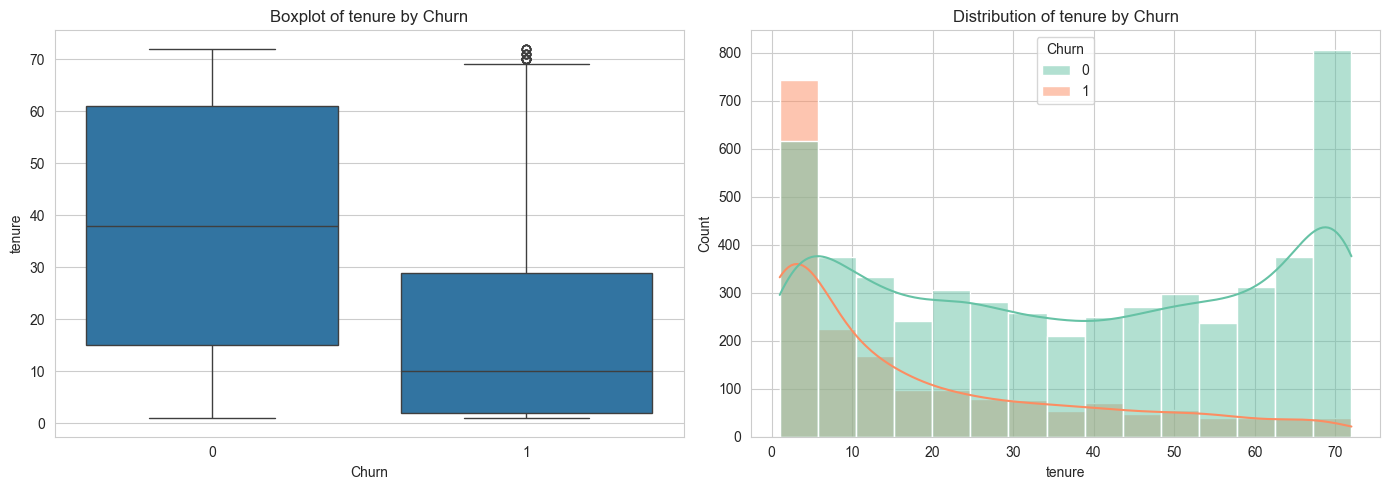

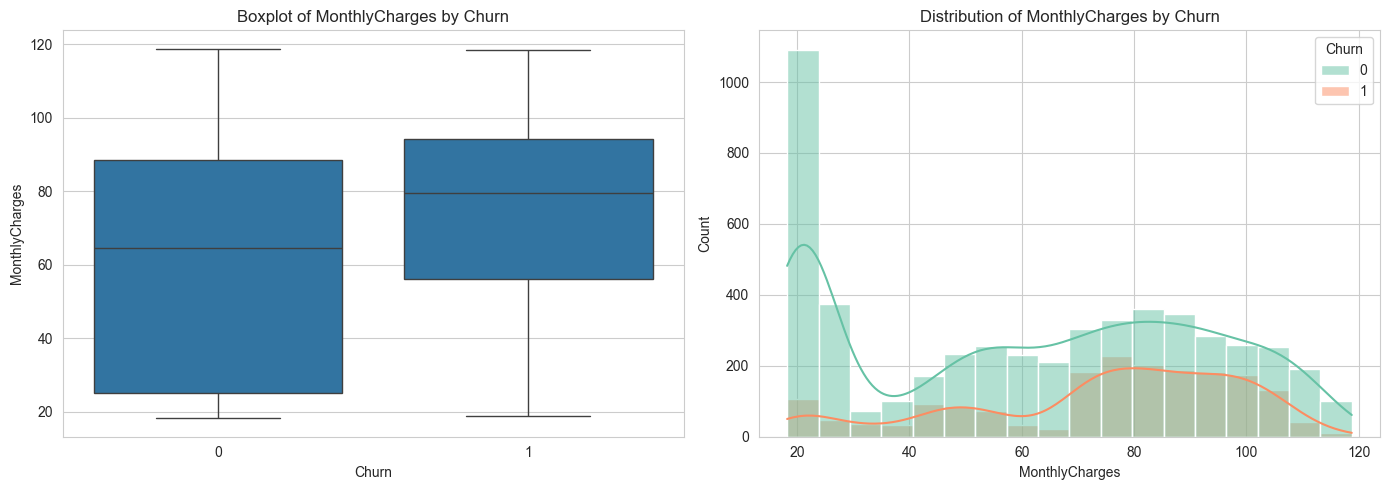

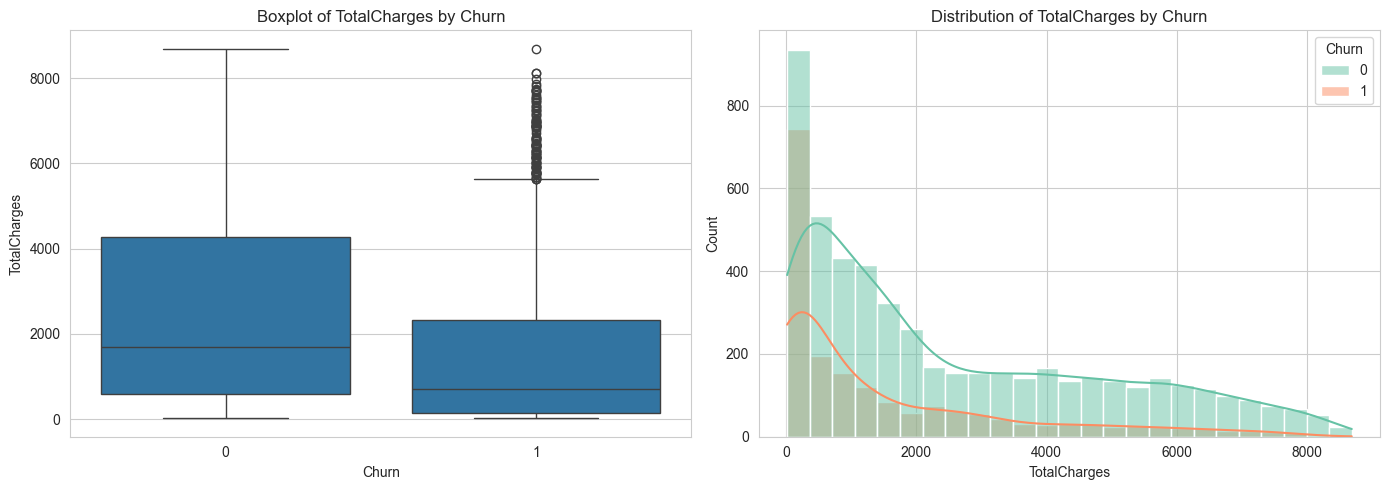

In [13]:
numerical_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
plot_numerical_vs_churn(df, numerical_cols)

Correlation Analysis

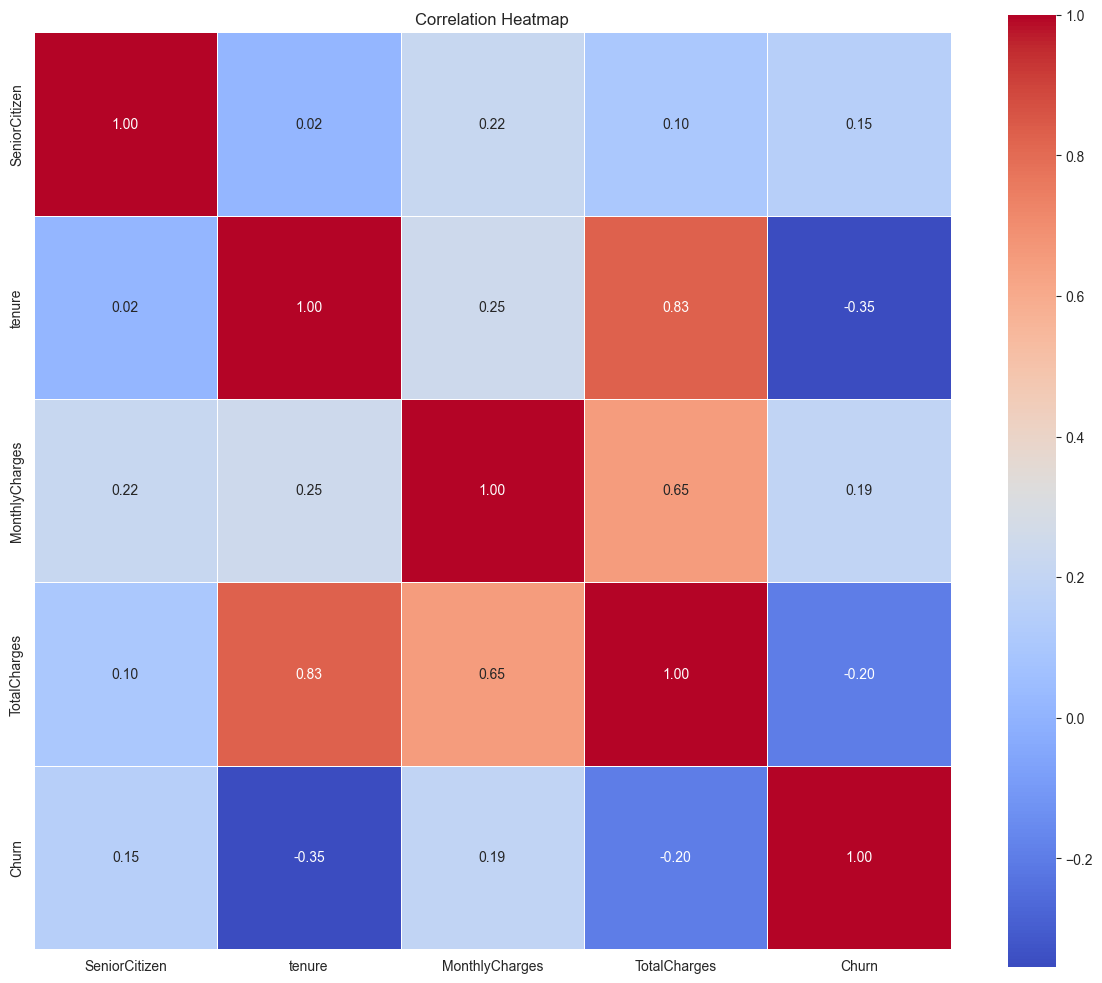

In [14]:
plot_correlation_heatmap(df)

### Key Insights

- Customers with **Month-to-month** contracts have significantly higher churn.
- **Fiber optic** internet users churn more than DSL users.
- Customers paying with **Electronic check** have higher churn.
- Higher **tenure** is strongly associated with lower churn.
- Customers with higher **MonthlyCharges** tend to churn more.
- Having **OnlineSecurity**, **TechSupport**, or **OnlineBackup** reduces churn probability.